### Importing necessary libraries

In [262]:
# %pip install pandas, numpy, seaborn, matplotlib, pillow, tqdm, scikit-learn, catboost
# %pip install -U ipywidgets 

In [263]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import PIL.Image as Image
import os, random, time
import math
from catboost import CatBoostClassifier, CatBoostRegressor
import tqdm
from tqdm.auto import tqdm

from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2_contingency

# Research Papers
1. [[PDF] Machine learning for risk stratification of thyroid cancer patients:
a 15‑year cohort study](research_papers\s00405-023-08299-w.pdf) ([[ONLINE] Paper link](https://link.springer.com/article/10.1007/s00405-023-08299-w))

In [264]:
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

pd.set_option('display.max_columns', None)
# colors = ["#078533", "#850728", "#fcba03"]
sns.set_palette(sns.color_palette("Set2"))

### Read dataset

In [265]:
DATA_PATH = [
                "./data/raw/1_differentiated_thyroid_cancer_recurrence.csv",
                "./data/raw/2_cirrhosis_patient_survival_prediction.csv",
                "./data/raw/3_glioma_grading_clinical_and_mutation_features.csv",
                "./data/raw/5_beed_bangalore_eeg_epilepsy_dataset",
                "./data/raw/6_cdc_diabetes_health_indicators"
]

df = pd.read_csv(DATA_PATH[0])
df_raw = df.copy()
print("Data frame shape:", df.shape)

Data frame shape: (383, 17)


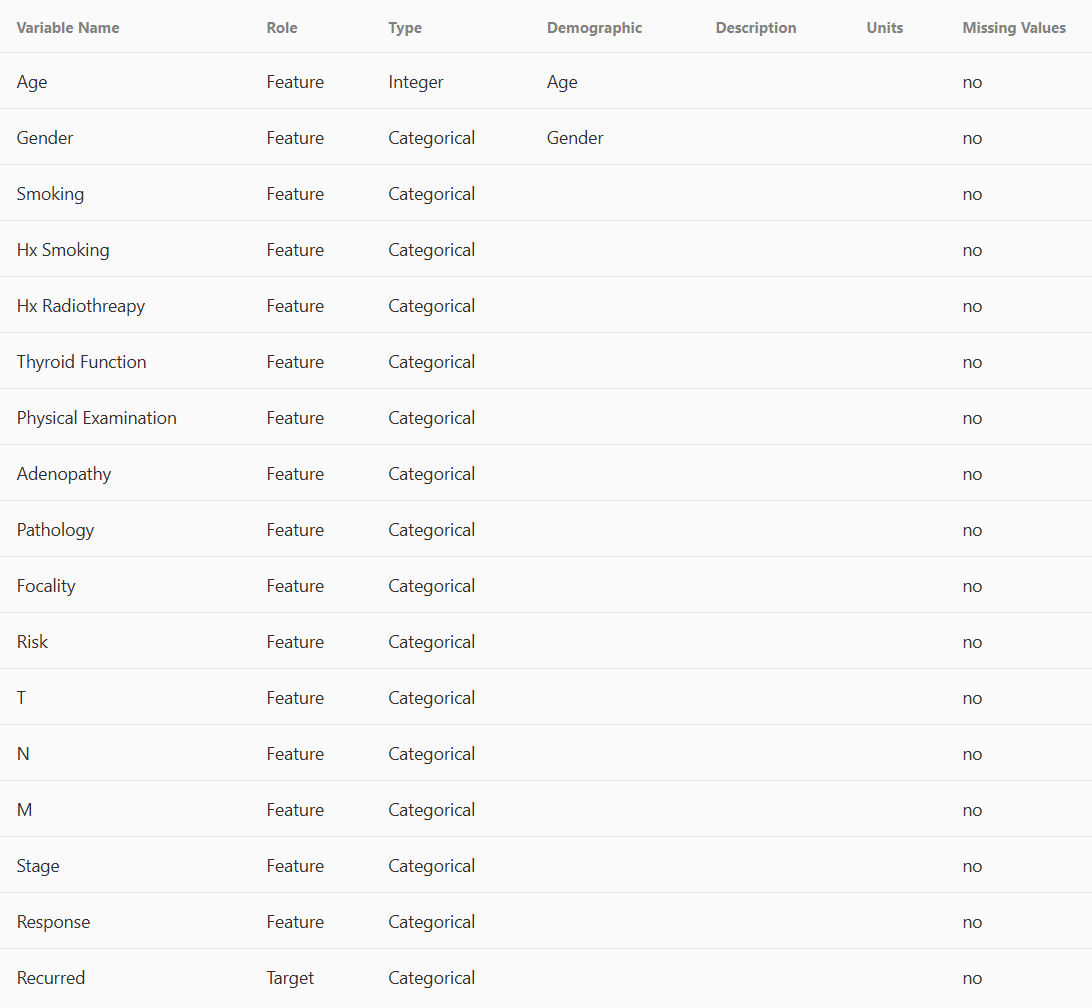

In [266]:
image = Image.open('./images/1_differentiated_thyroid_cancer_recurrence_variables_table.png')
display(image)

In [267]:
# Head 
display(df.head())

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
3,62,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
4,62,F,No,No,No,Euthyroid,Multinodular goiter,No,Micropapillary,Multi-Focal,Low,T1a,N0,M0,I,Excellent,No


In [268]:
# Tail 
display(df.tail())

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
378,72,M,Yes,Yes,Yes,Euthyroid,Single nodular goiter-right,Right,Papillary,Uni-Focal,High,T4b,N1b,M1,IVB,Biochemical Incomplete,Yes
379,81,M,Yes,No,Yes,Euthyroid,Multinodular goiter,Extensive,Papillary,Multi-Focal,High,T4b,N1b,M1,IVB,Structural Incomplete,Yes
380,72,M,Yes,Yes,No,Euthyroid,Multinodular goiter,Bilateral,Papillary,Multi-Focal,High,T4b,N1b,M1,IVB,Structural Incomplete,Yes
381,61,M,Yes,Yes,Yes,Clinical Hyperthyroidism,Multinodular goiter,Extensive,Hurthel cell,Multi-Focal,High,T4b,N1b,M0,IVA,Structural Incomplete,Yes
382,67,M,Yes,No,No,Euthyroid,Multinodular goiter,Bilateral,Papillary,Multi-Focal,High,T4b,N1b,M0,IVA,Structural Incomplete,Yes


### Sanity check of the dataset

In [269]:
# Dataset information
print("Dataframe info:")
df.info()

Dataframe info:
<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Age                   383 non-null    int64
 1   Gender                383 non-null    str  
 2   Smoking               383 non-null    str  
 3   Hx Smoking            383 non-null    str  
 4   Hx Radiothreapy       383 non-null    str  
 5   Thyroid Function      383 non-null    str  
 6   Physical Examination  383 non-null    str  
 7   Adenopathy            383 non-null    str  
 8   Pathology             383 non-null    str  
 9   Focality              383 non-null    str  
 10  Risk                  383 non-null    str  
 11  T                     383 non-null    str  
 12  N                     383 non-null    str  
 13  M                     383 non-null    str  
 14  Stage                 383 non-null    str  
 15  Response              383 non-null    str  
 16  Rec

In [270]:
# Finding missing values
df.isnull().sum()

Age                     0
Gender                  0
Smoking                 0
Hx Smoking              0
Hx Radiothreapy         0
Thyroid Function        0
Physical Examination    0
Adenopathy              0
Pathology               0
Focality                0
Risk                    0
T                       0
N                       0
M                       0
Stage                   0
Response                0
Recurred                0
dtype: int64

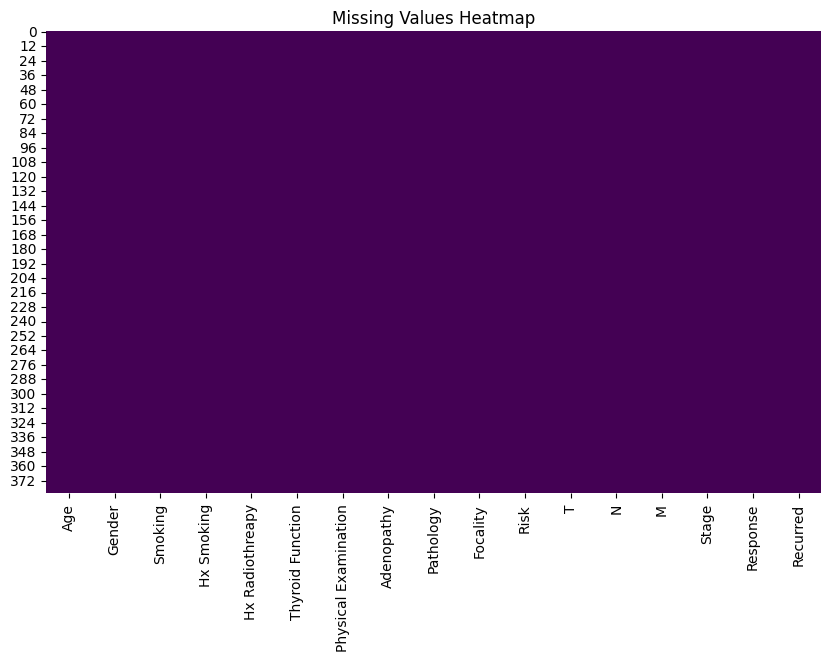

In [271]:
# Missing value visualization
plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

In [272]:
# Finding duplicate values
df.duplicated().sum()

np.int64(19)

### We are not dropping duplicates here because they are actual patient data not accidental duplicates. 
The research paper we are following also does not mention dropping duplicates.

In [273]:
# # Drop duplicate values
# df.drop_duplicates(inplace=True)
# print("Data frame shape after dropping duplicates:", df.shape)

In [274]:
# Identifying garbage values in categorical (object) columns
categorical_columns = df.select_dtypes(include=['object']).columns
for col in categorical_columns:
    print(f"Unique values in column '{col}': {df[col].unique()}")   
    print("----------------------------------------------------")

Unique values in column 'Gender': <StringArray>
['F', 'M']
Length: 2, dtype: str
----------------------------------------------------
Unique values in column 'Smoking': <StringArray>
['No', 'Yes']
Length: 2, dtype: str
----------------------------------------------------
Unique values in column 'Hx Smoking': <StringArray>
['No', 'Yes']
Length: 2, dtype: str
----------------------------------------------------
Unique values in column 'Hx Radiothreapy': <StringArray>
['No', 'Yes']
Length: 2, dtype: str
----------------------------------------------------
Unique values in column 'Thyroid Function': <StringArray>
[                  'Euthyroid',    'Clinical Hyperthyroidism',
     'Clinical Hypothyroidism', 'Subclinical Hyperthyroidism',
  'Subclinical Hypothyroidism']
Length: 5, dtype: str
----------------------------------------------------
Unique values in column 'Physical Examination': <StringArray>
[ 'Single nodular goiter-left',         'Multinodular goiter',
 'Single nodular goiter-r

C:\Users\Jonayed\AppData\Local\Temp\ipykernel_31524\1604347460.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object']).columns


# Exploratory Data Analysis (EDA)

In [275]:
LABEL = "Recurred"
NUM_FEATS = ["Age"]
CAT_FEATS = [x for x in df.columns if x not in NUM_FEATS and x != LABEL]
INP_FEATS = df.drop(LABEL, axis=1).columns.tolist() # original feats

# Descriptive statistics 
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,383.0,40.866841,15.134494,15.0,29.0,37.0,51.0,82.0


In [276]:
# Descriptive statistics for categorical columns
df.describe(include=['object', 'string']).T

,count,unique,top,freq
Gender,383,2,F,312
Smoking,383,2,No,334
Hx Smoking,383,2,No,355
Hx Radiothreapy,383,2,No,376
Thyroid Function,383,5,Euthyroid,332
Physical Examination,383,5,Multinodular goiter,140
Adenopathy,383,6,No,277
Pathology,383,4,Papillary,287
Focality,383,2,Uni-Focal,247
Risk,383,3,Low,249


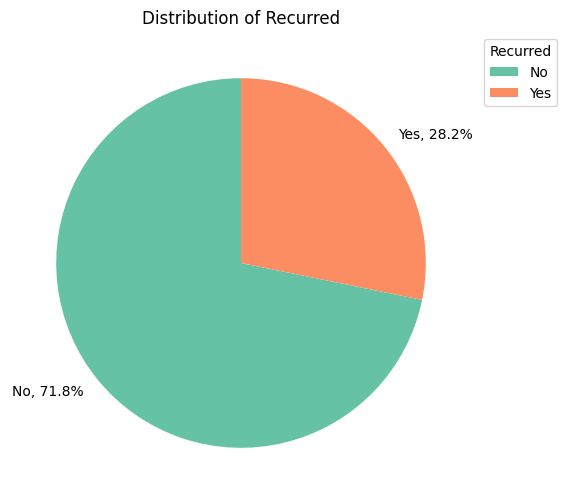

In [277]:
# Counting the observations for each category
status_counts = df[LABEL].value_counts()
labels = status_counts.index
sizes = status_counts.values

# Calculating the percentage of each category
percentages = 100.*sizes/sizes.sum()

# Creating the pie chart with percentages in the labels
plt.figure(figsize=(10, 6))
plt.pie(sizes, labels=[f"{l}, {s:.1f}%" for l, s in zip(labels, percentages)], startangle=90)
plt.gca().set_aspect("equal")
plt.legend(loc="upper right", bbox_to_anchor=(1.2, 1), labels=labels, title=LABEL)
plt.title(f"Distribution of {LABEL}")
plt.show()

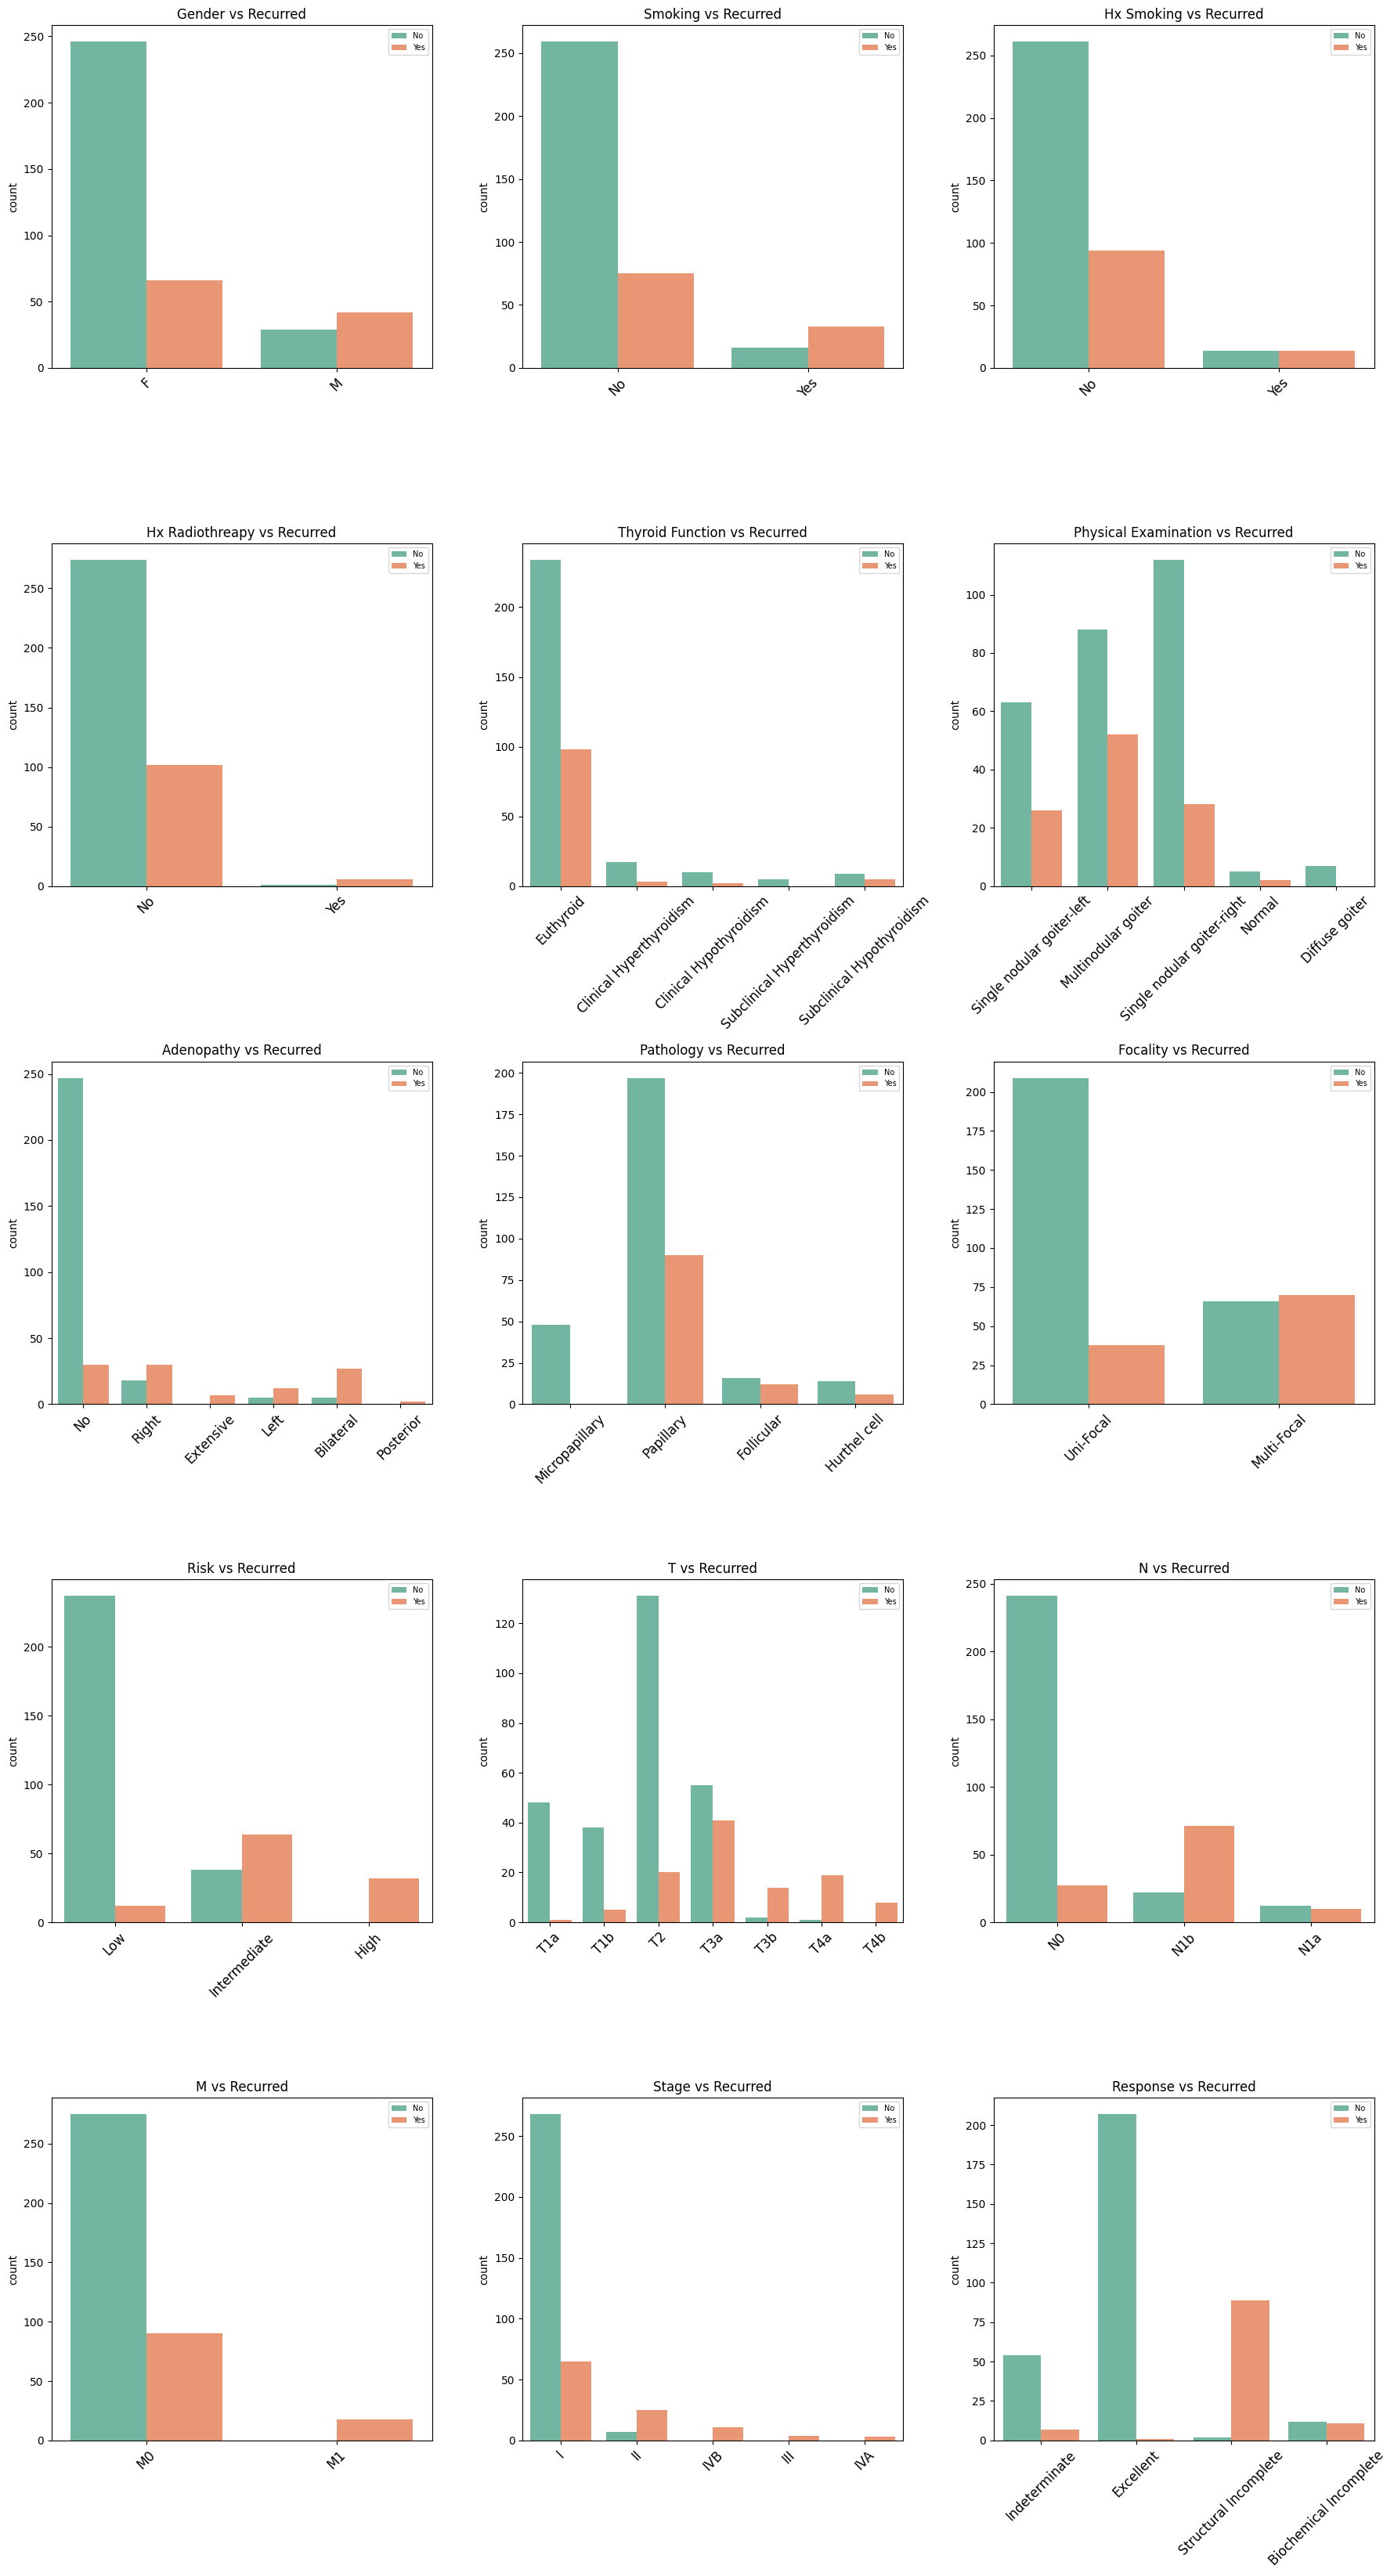

In [278]:
plt.figure(figsize=(18, len(CAT_FEATS) * 2.2))
nrows = math.ceil(len(CAT_FEATS) / 3)

for i, col in enumerate(CAT_FEATS):
    ax = plt.subplot(nrows, 3, i + 1)
    sns.countplot(x=col, hue=LABEL, data=df, ax=ax)
    ax.set_title(f"{col} vs {LABEL}")

    ax.tick_params(axis="x", labelrotation=45, labelsize=12)
    ax.set_xlabel("")
    ax.legend(fontsize=7)

plt.tight_layout()

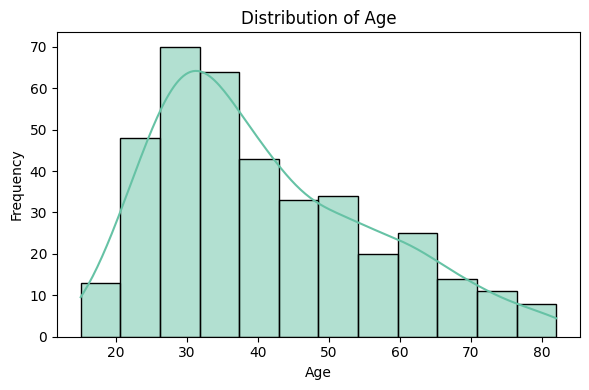

In [279]:
# Histograms to visualize distributions 
cols = [c for c in df.select_dtypes(include=[np.number]).columns]

# single numeric feature case
col = cols[0]

plt.figure(figsize=(6, 4))
sns.histplot(df[col].dropna(), kde=True)
plt.title(f"Distribution of {col}")
plt.xlabel(col)
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

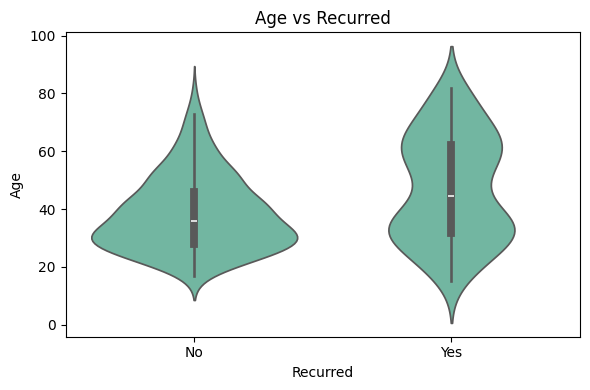

In [280]:
# violin plots for numerical features 
plt.figure(figsize=(6, 4))
sns.violinplot(x=LABEL, y=NUM_FEATS[0], data=df)
plt.title(f"{NUM_FEATS[0]} vs {LABEL}")
plt.tight_layout()
plt.show()


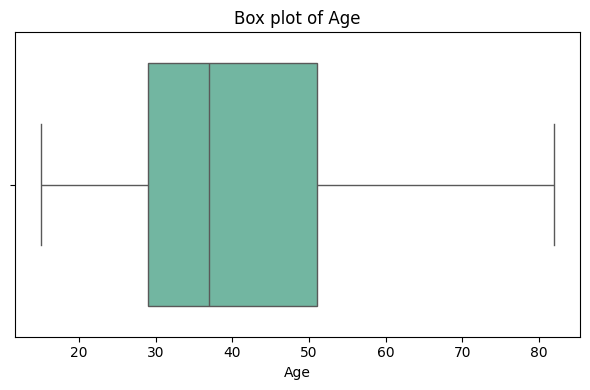

In [281]:
# Boxplot
cols = [c for c in df.select_dtypes(include=[np.number]).columns]

# single numeric feature case
col = cols[0]

plt.figure(figsize=(6, 4))
sns.boxplot(x=df[col])
plt.title(f"Box plot of {col}")
plt.xlabel(col)
plt.ylabel("")
plt.tight_layout()
plt.show()

In [282]:
# Correlation matrix
def cramers_v(x, y):
    tbl = pd.crosstab(x, y)
    if tbl.size == 0:
        return np.nan
    chi2, _, _, _ = chi2_contingency(tbl, correction=False)
    n = tbl.to_numpy().sum()
    r, k = tbl.shape
    if n == 0:
        return np.nan
    return np.sqrt((chi2 / n) / (min(k - 1, r - 1) if min(k - 1, r - 1) > 0 else np.nan))

cat_cols = CAT_FEATS  # your categorical columns
cv = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)

for a in cat_cols:
    for b in cat_cols:
        cv.loc[a, b] = 1.0 if a == b else cramers_v(df[a], df[b])

cv = cv.astype(float)

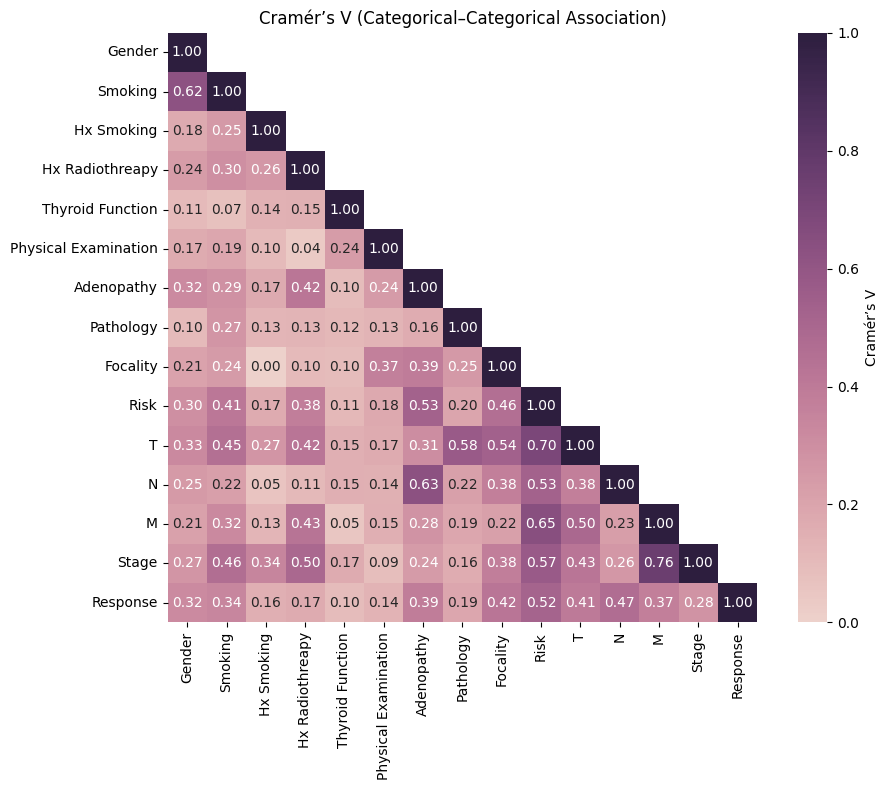

In [283]:
mask = np.triu(np.ones_like(cv, dtype=bool), k=1)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cv,
    mask=mask,          # hide upper triangle     
    vmin=0,
    vmax=1,
    cmap=sns.cubehelix_palette(as_cmap=True),
    annot=True,
    fmt=".2f",
    square=True,
    cbar_kws={"label": "Cramér’s V"}
)
plt.title("Cramér’s V (Categorical–Categorical Association)")
plt.tight_layout()
plt.show()


# Missing value treatment

In [284]:
# Null count check
df.isnull().sum()

Age                     0
Gender                  0
Smoking                 0
Hx Smoking              0
Hx Radiothreapy         0
Thyroid Function        0
Physical Examination    0
Adenopathy              0
Pathology               0
Focality                0
Risk                    0
T                       0
N                       0
M                       0
Stage                   0
Response                0
Recurred                0
dtype: int64

# Running a base model

In [285]:
# Use deduplicated data to avoid train/test leakage
df_model = df.copy()

# Optionally drop post-treatment leakage columns if present
leakage_cols = ["Response"]
df_model = df_model.drop(columns=[c for c in leakage_cols if c in df_model.columns])

# Split features/label
X = df_model.drop(columns=[LABEL])
y = df_model[LABEL]

# Encode target label
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include=["object", "string", "category"]).columns
num_cols = [c for c in X.columns if c not in cat_cols]

# Train-test split (match paper: 283 train / 100 validation)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=100,      # paper [1] uses 100 for validation
    train_size=283,
    random_state=42,
    stratify=y  # keeps class proportions similar in train/test
)

In [286]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Preprocess: scale numeric, one-hot encode categorical
numeric_transformer = Pipeline([
    ("scaler", StandardScaler())
])

categorical_transformer = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols),
    ],
    remainder="drop"
)

# Fit preprocessing on train only, then transform
X_train_proc = preprocess.fit_transform(X_train)
X_test_proc = preprocess.transform(X_test)

In [287]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(max_iter=5000)

# start timer
start_time = time.perf_counter()

# training
model.fit(X_train_proc, y_train)

# end timer
train_time = time.perf_counter() - start_time

# evaluation
y_pred = model.predict(X_test_proc)
acc = accuracy_score(y_test, y_pred)

print(f"Accuracy: {acc:.4f}")
print(f"Training time: {train_time:.6f} seconds")

Accuracy: 0.9100
Training time: 0.008969 seconds
